In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

In [8]:
df = pd.read_csv('C:\\Users\\nikki\\Desktop\\praca IT\\Portfolio\\Pokemon\\Pokemon.csv')

In [9]:
# Etap 1:Rozpoznanie danych i ich typów
df.head()

,#,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
0,1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False
1,2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,1,False
2,3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,1,False
3,3,VenusaurMega Venusaur,Grass,Poison,625,80,100,123,122,120,80,1,False
4,4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   #           800 non-null    int64
 1   Name        800 non-null    str  
 2   Type 1      800 non-null    str  
 3   Type 2      414 non-null    str  
 4   Total       800 non-null    int64
 5   HP          800 non-null    int64
 6   Attack      800 non-null    int64
 7   Defense     800 non-null    int64
 8   Sp. Atk     800 non-null    int64
 9   Sp. Def     800 non-null    int64
 10  Speed       800 non-null    int64
 11  Generation  800 non-null    int64
 12  Legendary   800 non-null    bool 
dtypes: bool(1), int64(9), str(3)
memory usage: 89.3 KB


In [11]:
df.shape

(800, 13)

In [12]:
df.describe()

,#,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation
count,800.000000,800.00000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.00000
mean,362.813750,435.10250,69.258750,79.001250,73.842500,72.820000,71.902500,68.277500,3.32375
std,208.343798,119.96304,25.534669,32.457366,31.183501,32.722294,27.828916,29.060474,1.66129
min,1.000000,180.00000,1.000000,5.000000,5.000000,10.000000,20.000000,5.000000,1.00000
25%,184.750000,330.00000,50.000000,55.000000,50.000000,49.750000,50.000000,45.000000,2.00000
50%,364.500000,450.00000,65.000000,75.000000,70.000000,65.000000,70.000000,65.000000,3.00000
75%,539.250000,515.00000,80.000000,100.000000,90.000000,95.000000,90.000000,90.000000,5.00000
max,721.000000,780.00000,255.000000,190.000000,230.000000,194.000000,230.000000,180.000000,6.00000


In [13]:
df.isnull().sum()

#               0
Name            0
Type 1          0
Type 2        386
Total           0
HP              0
Attack          0
Defense         0
Sp. Atk         0
Sp. Def         0
Speed           0
Generation      0
Legendary       0
dtype: int64

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
#Etap 2: Data Cleaning - przygotowanie danych do analizy
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_').str.replace('.', '', regex=False)

In [16]:
df.columns

Index(['#', 'name', 'type_1', 'type_2', 'total', 'hp', 'attack', 'defense',
       'sp_atk', 'sp_def', 'speed', 'generation', 'legendary'],
      dtype='str')

In [17]:
df.dtypes

#             int64
name            str
type_1          str
type_2          str
total         int64
hp            int64
attack        int64
defense       int64
sp_atk        int64
sp_def        int64
speed         int64
generation    int64
legendary      bool
dtype: object

In [18]:
df['calculated_total'] = df[['hp', 'attack', 'defense', 
                               'sp_atk', 'sp_def', 'speed']].sum(axis=1)

In [19]:
df[df['total'] != df['calculated_total']]

,#,name,type_1,type_2,total,hp,attack,defense,sp_atk,sp_def,speed,generation,legendary,calculated_total


In [20]:
df['number_of_types'] = np.where(df['type_2'].isnull(), 1, 2)

In [21]:
df['number_of_types'].value_counts()

number_of_types
2    414
1    386
Name: count, dtype: int64

The dataset contains 414 dual-type Pokemon (51.75%) and 386 single-type Pokemon (48.25%). Dual-type Pokemon slightly outnumber single-type Pokemon.

In [22]:
# Etap 3: Analiza danych - wizualizacja i interpretacja wyników
df[['hp', 'attack', 'defense', 'sp_atk', 'sp_def', 'speed', 'total']].describe()

,hp,attack,defense,sp_atk,sp_def,speed,total
count,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.00000
mean,69.258750,79.001250,73.842500,72.820000,71.902500,68.277500,435.10250
std,25.534669,32.457366,31.183501,32.722294,27.828916,29.060474,119.96304
min,1.000000,5.000000,5.000000,10.000000,20.000000,5.000000,180.00000
25%,50.000000,55.000000,50.000000,49.750000,50.000000,45.000000,330.00000
50%,65.000000,75.000000,70.000000,65.000000,70.000000,65.000000,450.00000
75%,80.000000,100.000000,90.000000,95.000000,90.000000,90.000000,515.00000
max,255.000000,190.000000,230.000000,194.000000,230.000000,180.000000,780.00000


### Descriptive Statistics – Key Findings

1. Attack has the highest average value among the six base stats (79.00), while Speed has the lowest average (68.28).

2. Special Attack has the highest standard deviation (32.72), indicating the greatest variability among Pokémon in this statistic.

3. HP has the lowest standard deviation (25.53), suggesting that this attribute is relatively less dispersed.

4. The average Total stat is 435.10, while the median is 450. This difference may indicate a left-skewed distribution.

5. The maximum HP value is 255, compared to an average of 69.26. This observation may indicate an extreme value worth investigating further.

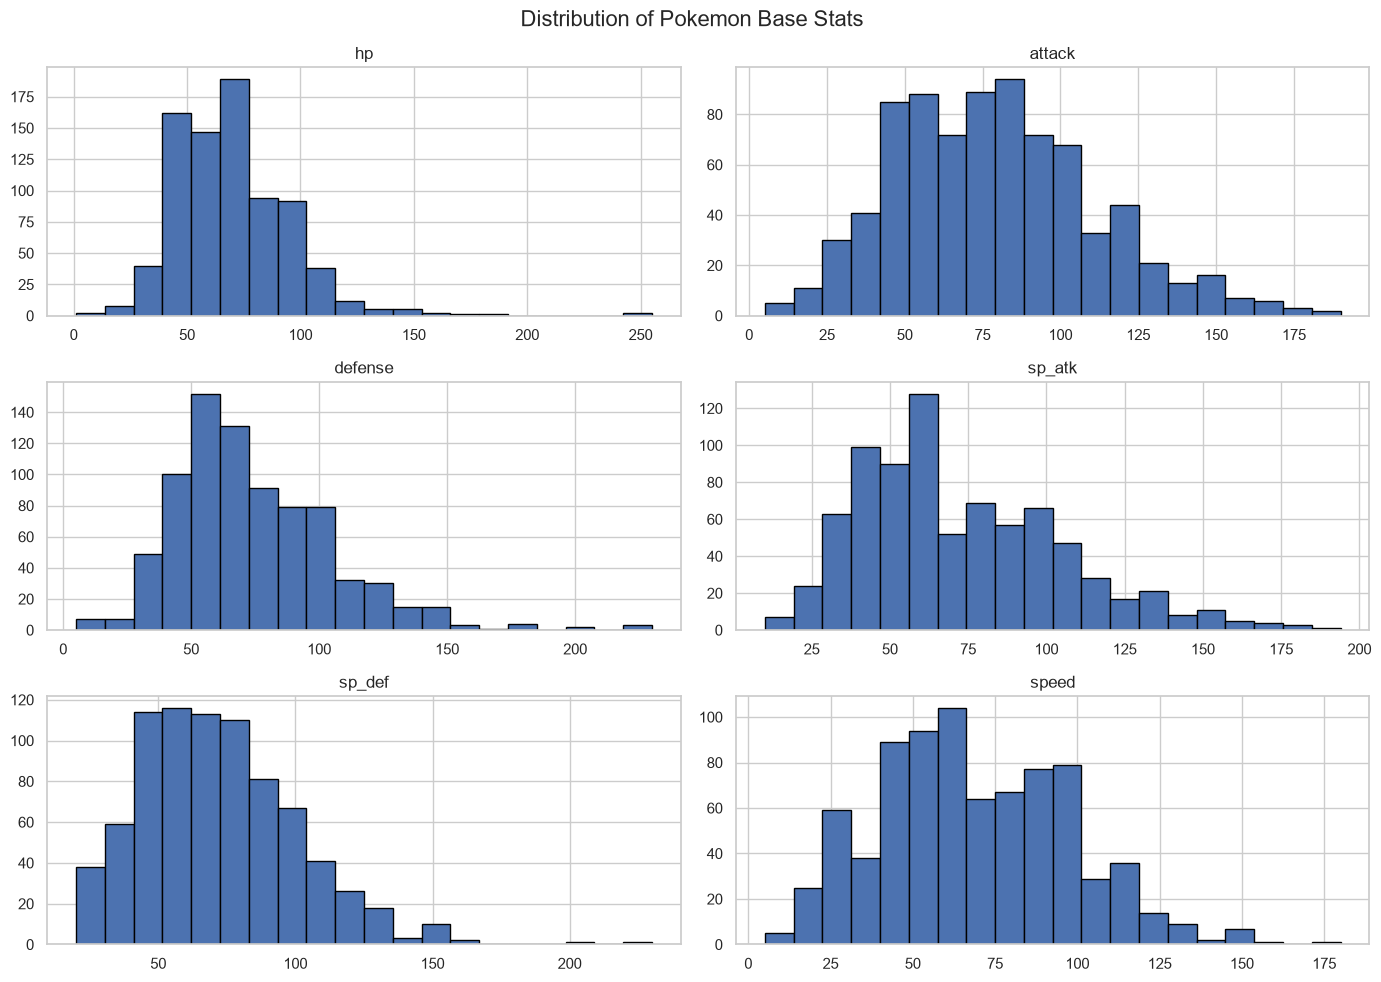

In [23]:
stats = ['hp', 'attack', 'defense', 'sp_atk', 'sp_def', 'speed']

df[stats].hist(bins=20, figsize=(14, 10), edgecolor='black')

plt.suptitle('Distribution of Pokemon Base Stats', fontsize=16)
plt.tight_layout()
plt.show()

In [24]:
df[stats].skew()

hp         1.568224
attack     0.551614
defense    1.155912
sp_atk     0.744662
sp_def     0.854019
speed      0.357933
dtype: float64

### Distribution Skewness Analysis

The skewness analysis revealed that all six Pokemon base stats have positively skewed distributions.

HP shows the highest skewness (1.57), followed by Defense (1.16). This indicates a longer right tail, suggesting that a relatively small number of Pokemon have exceptionally high values in these attributes.

Speed has the lowest skewness (0.36), making it the most symmetrical distribution among the analyzed attributes.

These findings suggest that extreme values influence the distribution of Pokemon base stats, particularly HP and Defense.

In [25]:
for col in stats:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col, len(outliers))

hp 19
attack 7
defense 13
sp_atk 10
sp_def 7
speed 2


### Outlier Detection – IQR Method

The IQR method identified potential outliers across all six base statistics.

HP contained the highest number of potential outliers (19), followed by Defense (13). Speed had the lowest number (2).

These observations indicate that extreme values occur more frequently in HP and Defense than in the other attributes.

Outliers were retained because extreme Pokemon statistics may represent valid observations rather than data entry errors.

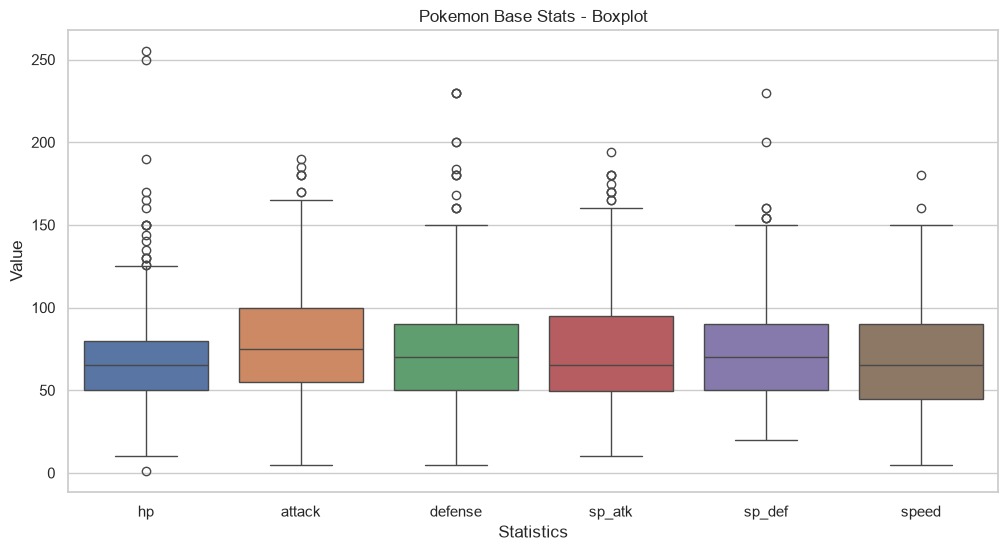

In [26]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=df[stats])

plt.title('Pokemon Base Stats - Boxplot')
plt.xlabel('Statistics')
plt.ylabel('Value')

plt.show()

In [27]:
type_counts = df['type_1'].value_counts()

print(type_counts)

type_1
Water       112
Normal       98
Grass        70
Bug          69
Psychic      57
Fire         52
Electric     44
Rock         44
Ground       32
Ghost        32
Dragon       32
Dark         31
Poison       28
Fighting     27
Steel        27
Ice          24
Fairy        17
Flying        4
Name: count, dtype: int64


In [28]:
type_percentage = df['type_1'].value_counts(normalize=True) * 100

print(type_percentage.round(2))

type_1
Water       14.00
Normal      12.25
Grass        8.75
Bug          8.62
Psychic      7.12
Fire         6.50
Electric     5.50
Rock         5.50
Ground       4.00
Ghost        4.00
Dragon       4.00
Dark         3.88
Poison       3.50
Fighting     3.38
Steel        3.38
Ice          3.00
Fairy        2.12
Flying       0.50
Name: proportion, dtype: float64


### Pokemon Distribution by Primary Type

Water is the most common primary Pokemon type, with 112 observations, followed by Normal with 98 observations.

Flying is the least represented type, with only 4 observations.

Water and Normal together account for 26.25% of all Pokemon in the dataset.

The distribution indicates that some Pokemon types are significantly more represented than others.

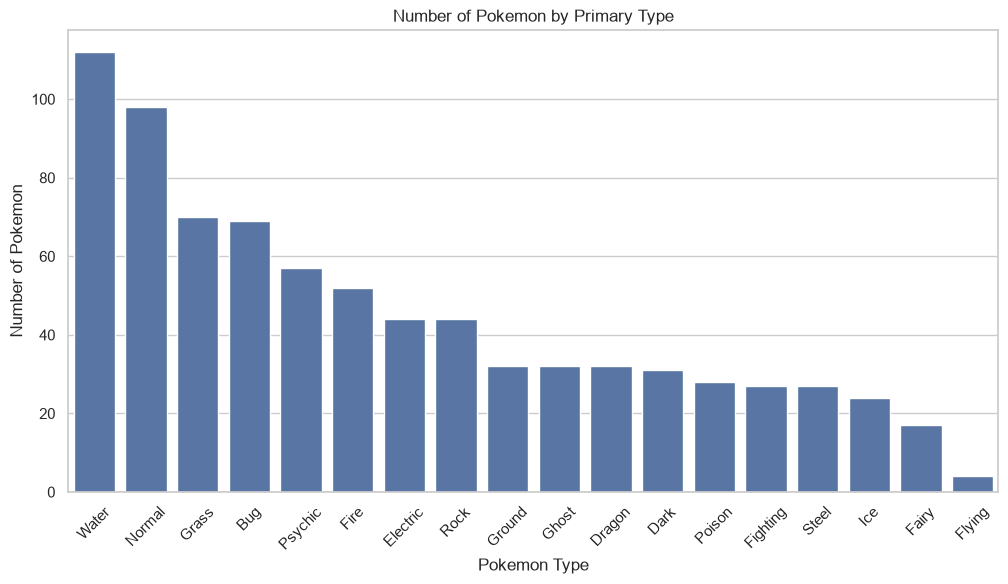

In [29]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=type_counts.index,
    y=type_counts.values
)

plt.title('Number of Pokemon by Primary Type')
plt.xlabel('Pokemon Type')
plt.ylabel('Number of Pokemon')

plt.xticks(rotation=45)
plt.show()

In [30]:
type_strength = df.groupby('type_1')['total'].mean()

print(type_strength)

type_1
Bug         378.927536
Dark        445.741935
Dragon      550.531250
Electric    443.409091
Fairy       413.176471
Fighting    416.444444
Fire        458.076923
Flying      485.000000
Ghost       439.562500
Grass       421.142857
Ground      437.500000
Ice         433.458333
Normal      401.683673
Poison      399.142857
Psychic     475.947368
Rock        453.750000
Steel       487.703704
Water       430.455357
Name: total, dtype: float64


In [31]:
type_strength = type_strength.sort_values(ascending=False)

print(type_strength)

type_1
Dragon      550.531250
Steel       487.703704
Flying      485.000000
Psychic     475.947368
Fire        458.076923
Rock        453.750000
Dark        445.741935
Electric    443.409091
Ghost       439.562500
Ground      437.500000
Ice         433.458333
Water       430.455357
Grass       421.142857
Fighting    416.444444
Fairy       413.176471
Normal      401.683673
Poison      399.142857
Bug         378.927536
Name: total, dtype: float64


### Average Pokemon Strenght by Type

Dragon is the strongest pokemon type in the dataset - average is 550,53.

Steel has second place with 487,70 score.

Water's score is 430,70 although its the biggest group of pokemon's type.


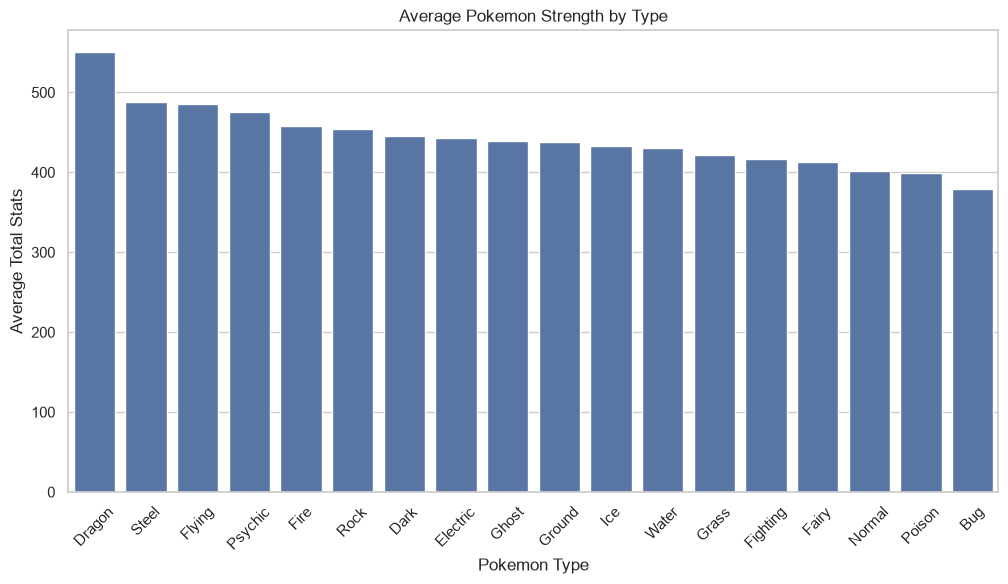

In [32]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=type_strength.index,
    y=type_strength.values
)

plt.title('Average Pokemon Strength by Type')
plt.xlabel('Pokemon Type')
plt.ylabel('Average Total Stats')

plt.xticks(rotation=45)
plt.show()

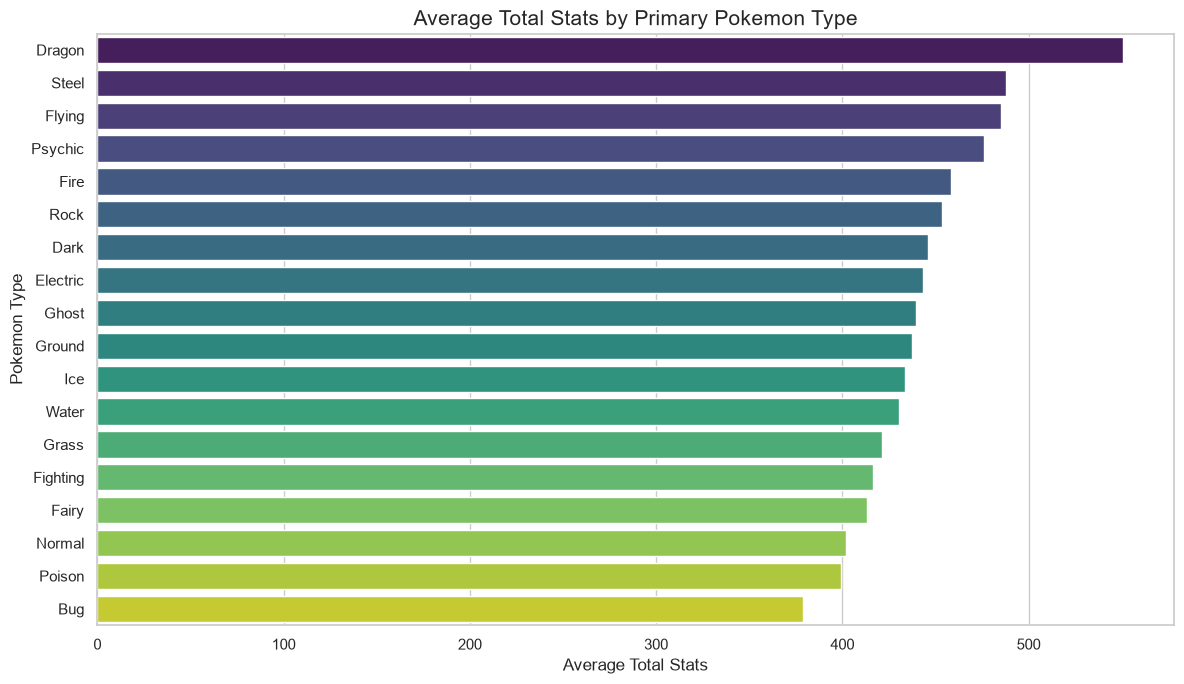

In [33]:
plt.figure(figsize=(12, 7))

sns.barplot(
    x=type_strength.values,
    y=type_strength.index,
    hue=type_strength.index,
    palette='viridis',
    legend=False
)

plt.title('Average Total Stats by Primary Pokemon Type',
          fontsize=15)
plt.xlabel('Average Total Stats')
plt.ylabel('Pokemon Type')

plt.tight_layout()
plt.show()

In [34]:
df.groupby('type_1')['legendary'].agg(
    ['count', 'sum', 'mean']
).sort_values('mean', ascending=False)

,count,sum,mean
type_1,,,
Flying,4,2,0.500000
Dragon,32,12,0.375000
Psychic,57,14,0.245614
Steel,27,4,0.148148
Ground,32,4,0.125000
Fire,52,5,0.096154
Rock,44,4,0.090909
Electric,44,4,0.090909
Ice,24,2,0.083333


In [35]:
dragon = df[df['type_1'] == 'Dragon']

print("Wszyscy:")
print(dragon['total'].mean())

print("Bez legendarnych:")
print(dragon[dragon['legendary'] == False]['total'].mean())

Wszyscy:
550.53125
Bez legendarnych:
476.85


In [36]:
non_legendary = df[df['legendary'] == False]

type_strength_non_legendary = (
    non_legendary.groupby('type_1')['total']
    .mean()
    .sort_values(ascending=False)
)

print(type_strength_non_legendary.round(2))

type_1
Dragon      476.85
Steel       466.43
Fire        442.13
Rock        437.62
Dark        432.34
Electric    429.75
Ghost       423.53
Psychic     423.00
Water       421.40
Ice         420.14
Fighting    416.44
Grass       413.43
Ground      405.71
Poison      399.14
Fairy       396.50
Normal      395.57
Flying      390.00
Bug         378.93
Name: total, dtype: float64


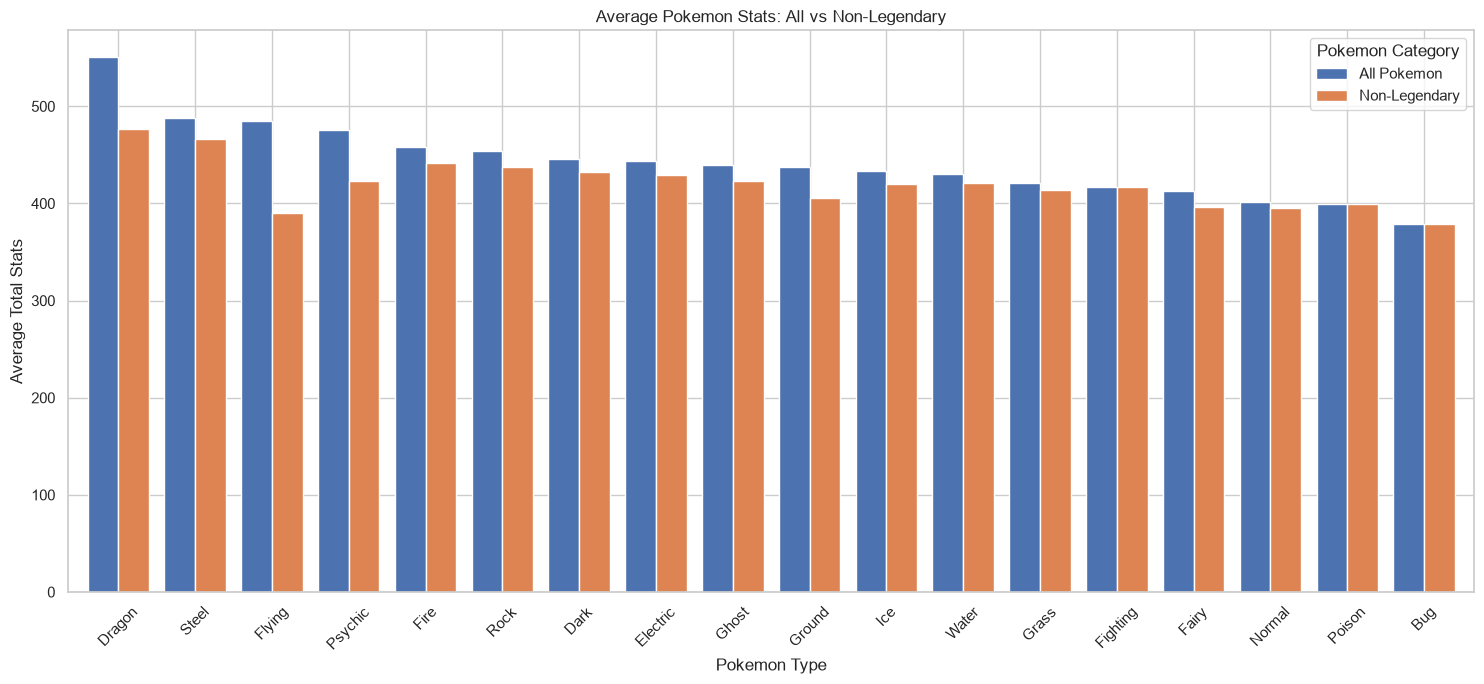

In [37]:
comparison = pd.DataFrame({
    'All Pokemon': df.groupby('type_1')['total'].mean(),
    'Non-Legendary': df[df['legendary'] == False]
        .groupby('type_1')['total'].mean()
})

comparison = comparison.sort_values('All Pokemon', ascending=False)

comparison.plot(
    kind='bar',
    figsize=(15, 7),
    width=0.8
)

plt.title('Average Pokemon Stats: All vs Non-Legendary')
plt.xlabel('Pokemon Type')
plt.ylabel('Average Total Stats')
plt.xticks(rotation=45)
plt.legend(title='Pokemon Category')
plt.tight_layout()
plt.show()

In [38]:
df.groupby('type_1')['total'].agg(
    ['count', 'min', 'max', 'mean', 'median']
).sort_values('mean', ascending=False)

,count,min,max,mean,median
type_1,,,,,
Dragon,32,300,780,550.531250,600.0
Steel,27,300,700,487.703704,500.0
Flying,4,245,580,485.000000,557.5
Psychic,57,198,780,475.947368,485.0
Fire,52,250,680,458.076923,482.0
Rock,44,280,700,453.750000,467.5
Dark,31,220,680,445.741935,465.0
Electric,44,205,610,443.409091,477.5
Ghost,32,275,680,439.562500,464.5


# Korelacje
Correlations questions:
1. Has Pokemons with high Attack has high Defense?
2. Is Speed correlated with Attack?
3. Which statistics are the most correlated?


In [39]:
stats = ['hp', 'attack', 'defense', 'sp_atk', 'sp_def', 'speed']

correlation = df[stats].corr(method='pearson')

correlation.round(2)


,hp,attack,defense,sp_atk,sp_def,speed
hp,1.00,0.42,0.24,0.36,0.38,0.18
attack,0.42,1.00,0.44,0.40,0.26,0.38
defense,0.24,0.44,1.00,0.22,0.51,0.02
sp_atk,0.36,0.40,0.22,1.00,0.51,0.47
sp_def,0.38,0.26,0.51,0.51,1.00,0.26
speed,0.18,0.38,0.02,0.47,0.26,1.00


Correlations answer:
1. Do Pokémon with high Attack also have high Defense?

Yes, there is a moderate positive correlation between Attack and Defense (r = 0.44). This suggests that Pokémon with higher Attack tend to have higher Defense, although this relationship is not particularly strong.

2. Is Speed correlated with Attack?

Yes, Attack and Speed have a moderate positive correlation (r = 0.38). This means that Pokémon with higher Attack tend to have slightly higher Speed, but there are many exceptions.

3. Which statistics are the most correlated?

The strongest positive correlations are:
- Defense and Sp. Def: r = 0.51
- Sp. Atk and Sp. Def: r = 0.51
- Sp. Atk and Speed: r = 0.47
The strongest relationship is shared by two pairs: Defense–Sp. Def and Sp. Atk–Sp. Def.
Overall conclusion
The correlation analysis shows that Pokémon base stats have mostly weak to moderate positive linear relationships. No pair demonstrates a strong correlation. Defense and Sp. Def, as well as Sp. Atk and Sp. Def, show the strongest relationship

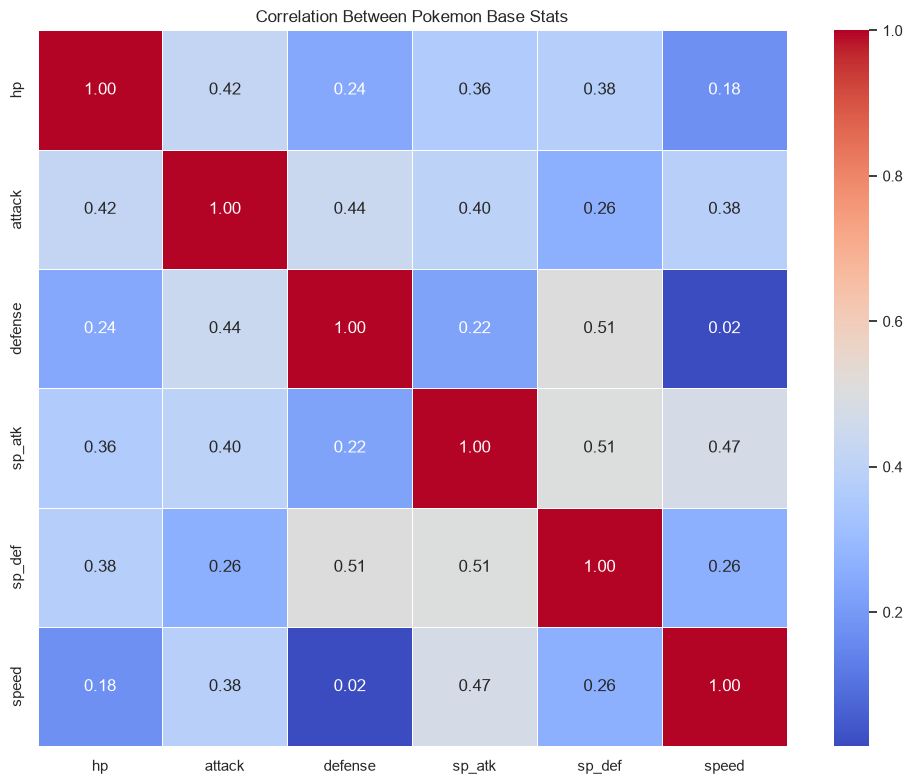

In [40]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Between Pokemon Base Stats')
plt.tight_layout()
plt.show()

In [41]:
legendary_comparison = df.groupby('legendary')[
    ['hp', 'attack', 'defense', 'sp_atk', 'sp_def', 'speed', 'total']
].mean()

legendary_comparison.round(2)

,hp,attack,defense,sp_atk,sp_def,speed,total
legendary,,,,,,,
False,67.18,75.67,71.56,68.45,68.89,65.46,417.21
True,92.74,116.68,99.66,122.18,105.94,100.18,637.38


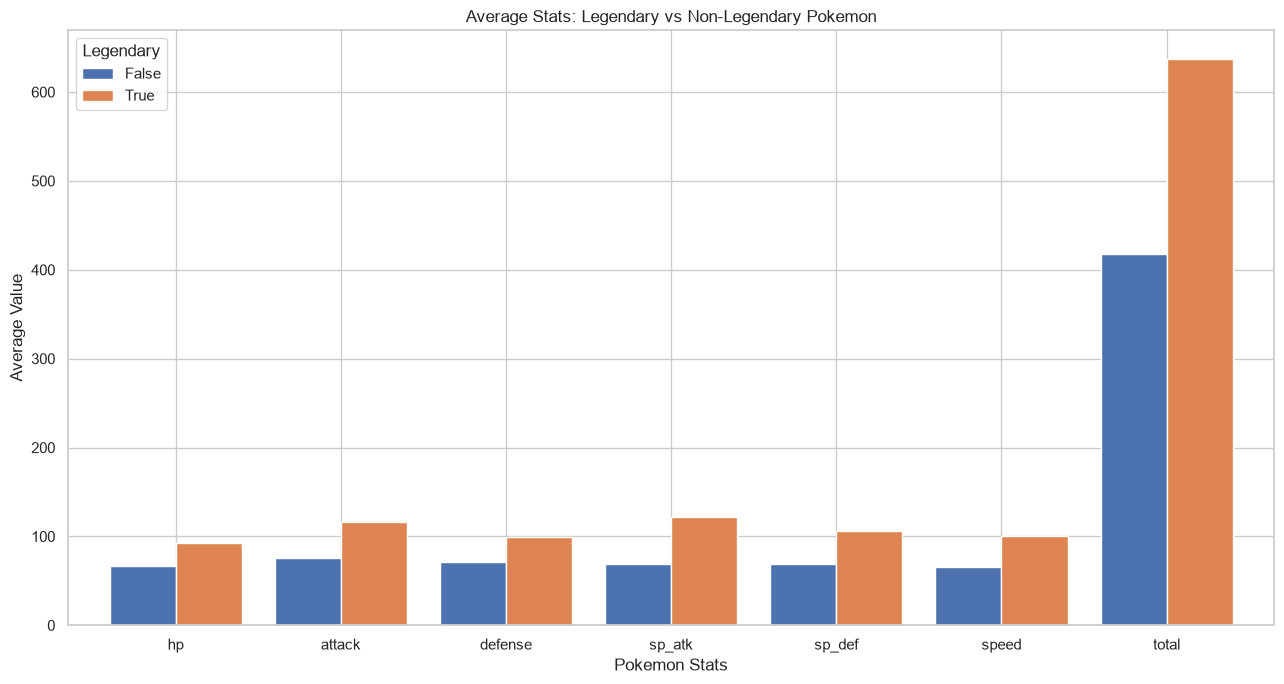

In [42]:
legendary_comparison.T.plot(
    kind='bar',
    figsize=(13, 7),
    width=0.8
)

plt.title('Average Stats: Legendary vs Non-Legendary Pokemon')
plt.xlabel('Pokemon Stats')
plt.ylabel('Average Value')
plt.xticks(rotation=0)
plt.legend(title='Legendary')
plt.tight_layout()
plt.show()

In [43]:
df['legendary'].value_counts()

legendary
False    735
True      65
Name: count, dtype: int64

In [44]:
df['legendary'].value_counts(normalize=True).mul(100).round(2)

legendary
False    91.88
True      8.12
Name: proportion, dtype: float64

The groups are unequal in size: there are 735 non-legendary Pokémon and only 65 legendary ones.

Averages for the legendary group are used to account for potential risks.

Despite the differences in group size, all the statistics analyzed are higher for the legendary Pokémon.

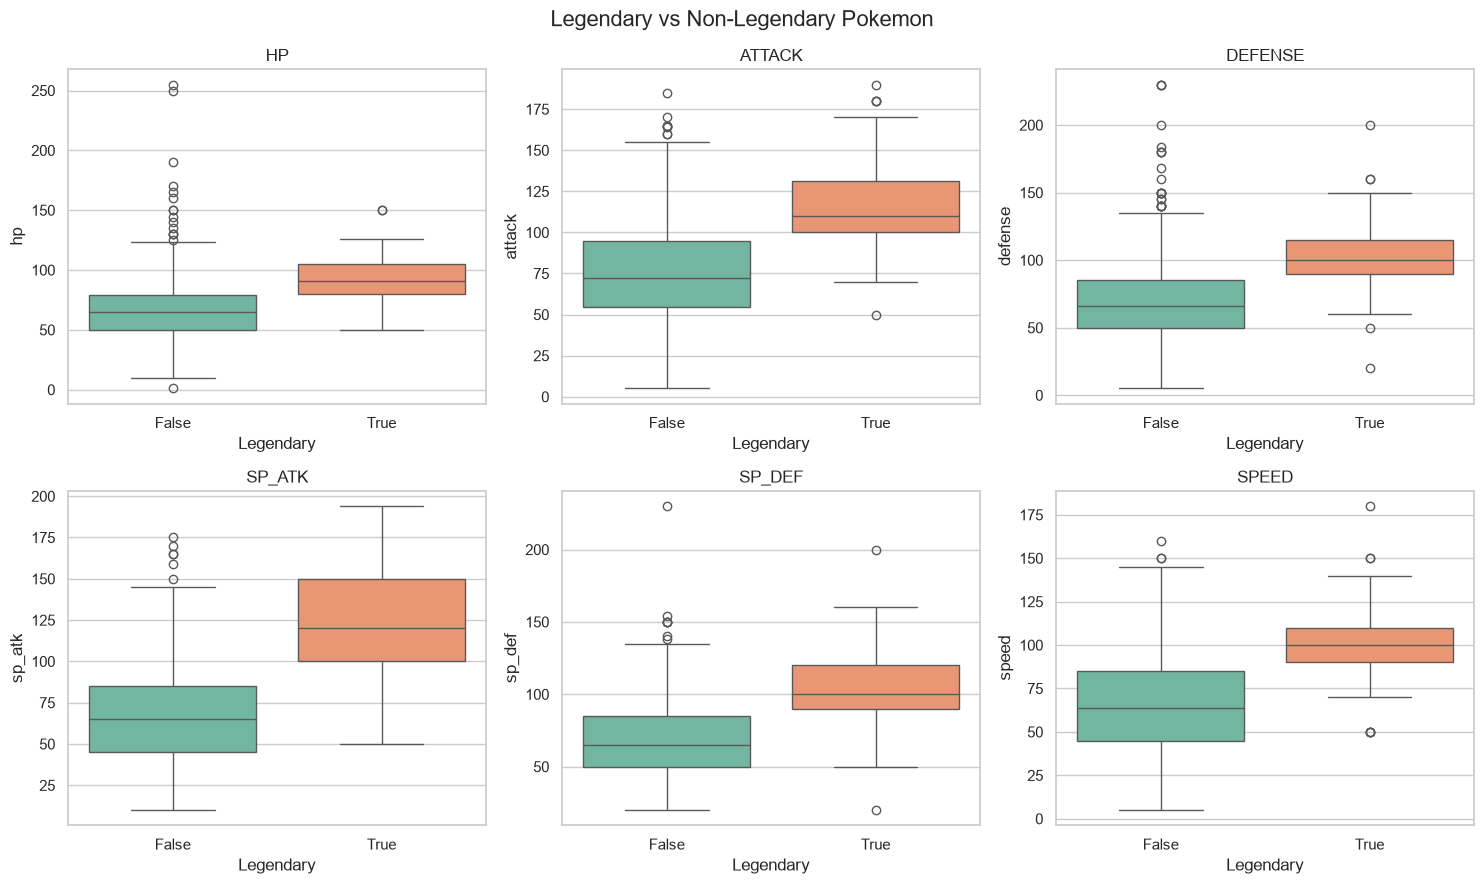

In [46]:
stats = ['hp', 'attack', 'defense',
         'sp_atk', 'sp_def', 'speed']

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for col, ax in zip(stats, axes.flatten()):
    sns.boxplot(
        data=df,
        x='legendary',
        y=col,
        hue='legendary',
        palette='Set2',
        legend=False,
        ax=ax
    )
    ax.set_title(col.upper())
    ax.set_xlabel('Legendary')

plt.suptitle('Legendary vs Non-Legendary Pokemon', fontsize=16)
plt.tight_layout()
plt.show()

In [47]:
df.groupby('legendary')['attack'].agg(
    ['min', 'max', 'median']
)

,min,max,median
legendary,,,
False,5,185,72.0
True,50,190,110.0


Legendary Pokémon demonstrate a higher median Attack value (110) compared to non-legendary Pokémon (72). However, the ranges overlap considerably, indicating that some non-legendary Pokémon can have higher Attack values than certain legendary Pokémon.

In [48]:
generation_stats = df.groupby('generation')['total'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

generation_stats.round(2)

,count,mean,median,min,max
generation,,,,,
1,166,426.81,436.5,195,780
2,106,418.28,422.5,180,700
3,160,436.22,435.0,190,780
4,121,459.02,485.0,194,720
5,165,434.99,465.0,255,700
6,82,436.38,464.0,200,700


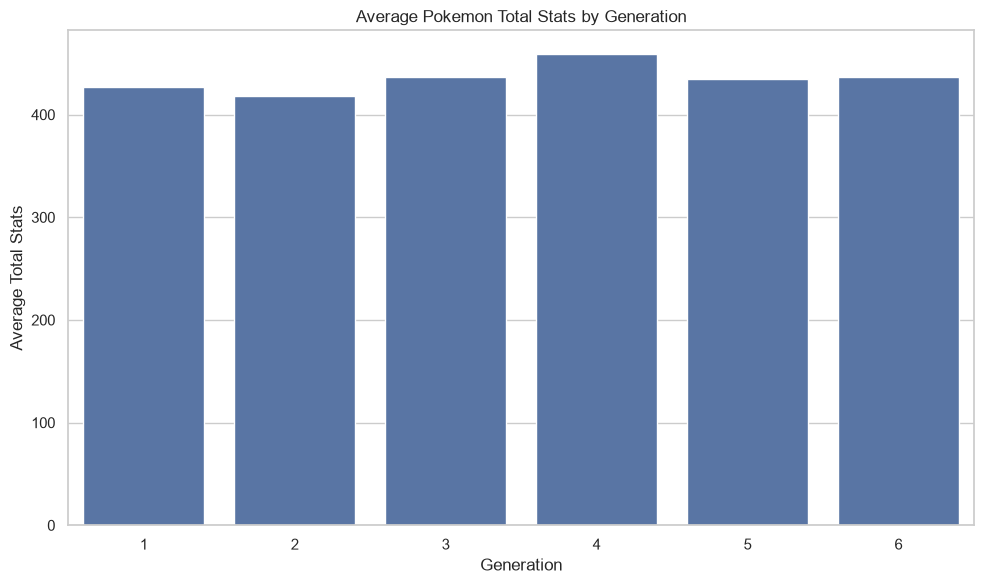

In [49]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x='generation',
    y='total',
    estimator='mean',
    errorbar=None
)

plt.title('Average Pokemon Total Stats by Generation')
plt.xlabel('Generation')
plt.ylabel('Average Total Stats')
plt.tight_layout()
plt.show()

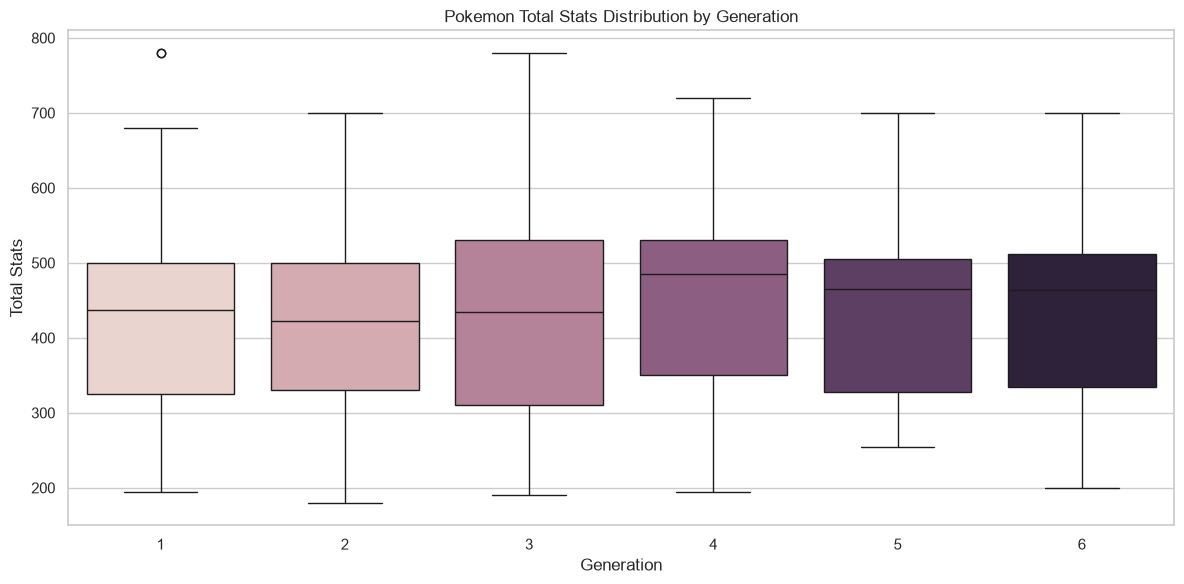

In [50]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x='generation',
    y='total',
    hue='generation',
    legend=False
)

plt.title('Pokemon Total Stats Distribution by Generation')
plt.xlabel('Generation')
plt.ylabel('Total Stats')
plt.tight_layout()
plt.show()

In [51]:
type_comparison = df.groupby('number_of_types')['total'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)

type_comparison.round(2)

,count,mean,median,std,min,max
number_of_types,,,,,,
1,386,412.02,410.0,114.75,180,780
2,414,456.63,475.0,120.85,190,780


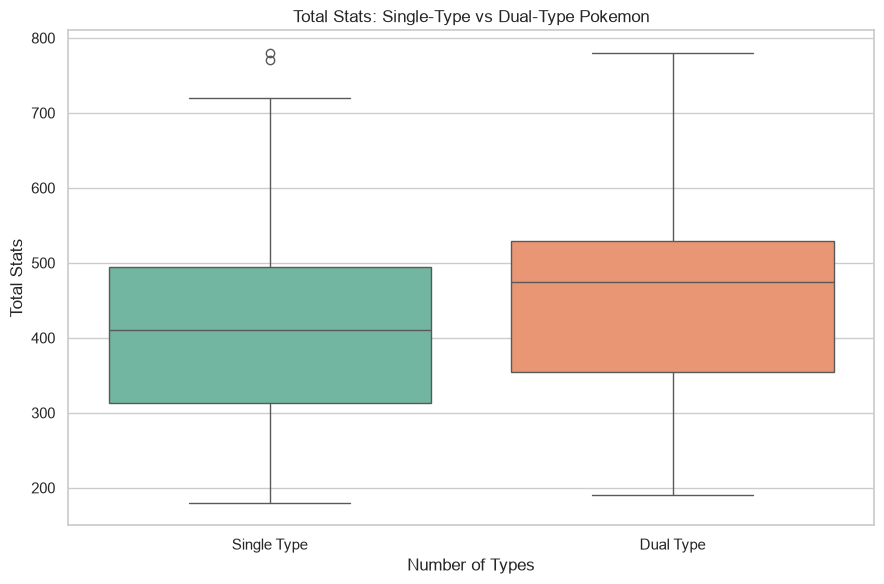

In [52]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x='number_of_types',
    y='total',
    hue='number_of_types',
    palette='Set2',
    legend=False
)

plt.title('Total Stats: Single-Type vs Dual-Type Pokemon')
plt.xlabel('Number of Types')
plt.ylabel('Total Stats')
plt.xticks([0, 1], ['Single Type', 'Dual Type'])
plt.tight_layout()
plt.show()


Key observations
1. Dual-type Pokémon have, on average, a total stat value that is 44.61 points higher.
2. Their median is 65 points higher.
3. The standard deviation is slightly higher in the dual-type group (120.85 vs. 114.75).
4. Both groups share the same maximum value – 780.